In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel("Dataset_A5.xlsx")

B1. Load and Explore

In [3]:
print(df.head())

                Timestamp division height_cm height_in weight_kg weight_lb
0 2026-08-22 15:43:04.048     TY-B       164      5.45        72       158
1 2026-08-22 15:43:20.944     TY-B       177        70        71       154
2 2026-08-22 15:43:21.342     TY-B       180        70        54       119
3 2026-08-22 15:43:35.510     TY-B       180        71        68       150
4 2026-08-22 15:43:44.474     TY-A       180       NaN        85       NaN


In [4]:
print(df.shape)

(156, 6)


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Timestamp  156 non-null    datetime64[ns]
 1   division   155 non-null    object        
 2   height_cm  155 non-null    object        
 3   height_in  145 non-null    object        
 4   weight_kg  155 non-null    object        
 5   weight_lb  142 non-null    object        
dtypes: datetime64[ns](1), object(5)
memory usage: 7.4+ KB
None


In [6]:
print(df.isnull().sum())

Timestamp     0
division      1
height_cm     1
height_in    11
weight_kg     1
weight_lb    14
dtype: int64


In [7]:
df["height_cm"] = pd.to_numeric(df["height_cm"], errors="coerce")
df["height_in"] = pd.to_numeric(df["height_in"], errors="coerce")

In [8]:
df["weight_kg"] = pd.to_numeric(df["weight_kg"], errors="coerce")
df["weight_lb"] = pd.to_numeric(df["weight_lb"], errors="coerce")

In [9]:
df = df.dropna()

In [10]:
df_a = df[df["division"] == "TY-A"]
df_b = df[df["division"] == "TY-B"]

In [11]:
print("TY-A:")
print(df_a.head())

TY-A:
                 Timestamp division  height_cm  height_in  weight_kg  \
7  2026-08-22 15:44:22.552     TY-A     170.00    67.0000      64.00   
9  2026-08-22 15:44:36.601     TY-A     169.00    66.5354      55.00   
14 2026-08-22 15:46:45.841     TY-A     182.00    71.6500      67.46   
20 2026-08-22 15:51:05.775     TY-A     176.00    69.2900      73.00   
32 2026-08-22 16:22:05.116     TY-A     181.88    72.0000      77.00   

    weight_lb  
7     141.000  
9     121.254  
14    148.720  
20    161.000  
32    169.000  


In [12]:
print("TY-B:")
print(df_b.head())

TY-B:
                Timestamp division  height_cm  height_in  weight_kg  weight_lb
0 2026-08-22 15:43:04.048     TY-B      164.0       5.45       72.0     158.00
1 2026-08-22 15:43:20.944     TY-B      177.0      70.00       71.0     154.00
2 2026-08-22 15:43:21.342     TY-B      180.0      70.00       54.0     119.00
3 2026-08-22 15:43:35.510     TY-B      180.0      71.00       68.0     150.00
5 2026-08-22 15:43:45.108     TY-B      180.0       5.90       68.0     149.91


In [13]:
height_a = df_a["height_cm"].mean()
height_b = df_b["height_cm"].mean()

In [14]:

weight_a = df_a["weight_kg"].mean()
weight_b = df_b["weight_kg"].mean()

In [15]:
print("TY-A average height:", height_a)
print("TY-B average height:", height_b)

TY-A average height: 168.49960000000002
TY-B average height: 172.7053857142857


In [16]:
print("TY-A average weight:", weight_a)
print("TY-B average weight:", weight_b)

TY-A average weight: 60.4252
TY-B average weight: 63.011428571428574


TY B Has higher average height and same for weight

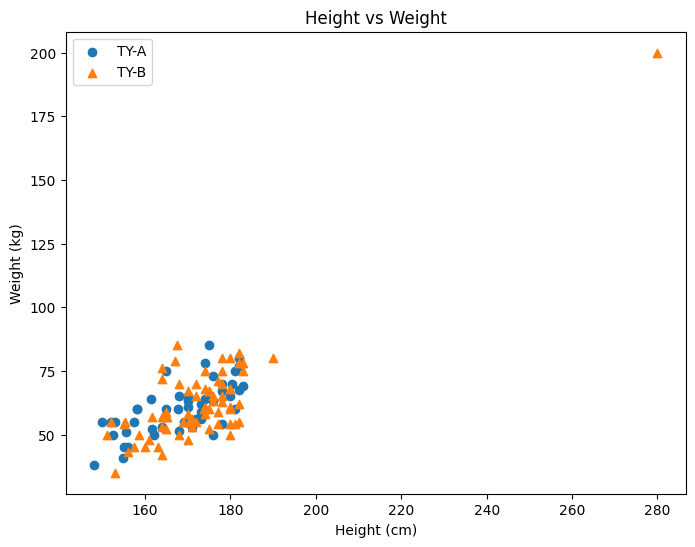

In [17]:
plt.figure(figsize=(8,6))

plt.scatter(df_a["height_cm"], df_a["weight_kg"], marker="o", label="TY-A")
plt.scatter(df_b["height_cm"], df_b["weight_kg"], marker="^", label="TY-B")

plt.title("Height vs Weight")
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.legend()
plt.show()

Positive linear relationship 
They both are clearly overlaping which means no clear difference is seen


B2 Correlation Analysis


           height_cm  height_in  weight_kg  weight_lb
height_cm   1.000000   0.119917   0.675635   0.675208
height_in   0.119917   1.000000   0.053967   0.054860
weight_kg   0.675635   0.053967   1.000000   0.999723
weight_lb   0.675208   0.054860   0.999723   1.000000


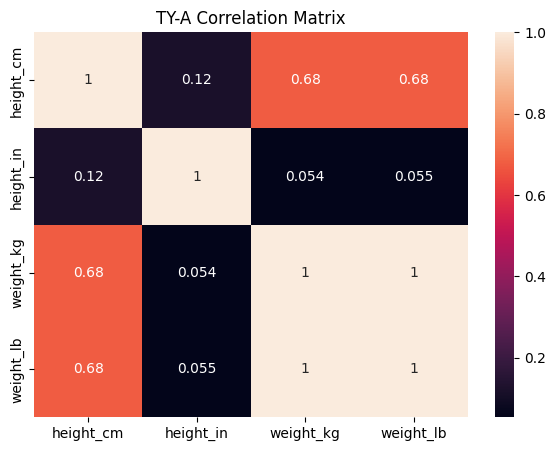

In [19]:
corr_a = df_a[["height_cm", "height_in", "weight_kg", "weight_lb"]].corr()

print(corr_a)

plt.figure(figsize=(7,5))
sns.heatmap(corr_a, annot=True)

plt.title("TY-A Correlation Matrix")
plt.show()


           height_cm  height_in  weight_kg  weight_lb
height_cm   1.000000  -0.146087   0.864292   0.793187
height_in  -0.146087   1.000000  -0.138580  -0.135383
weight_kg   0.864292  -0.138580   1.000000   0.921846
weight_lb   0.793187  -0.135383   0.921846   1.000000


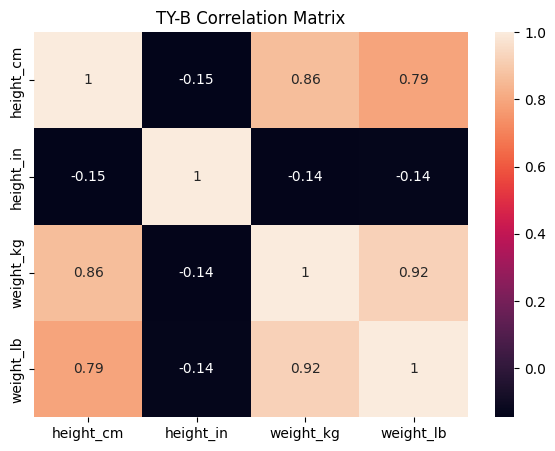

In [20]:
corr_b = df_b[["height_cm", "height_in", "weight_kg", "weight_lb"]].corr()

print(corr_b)

plt.figure(figsize=(7,5))
sns.heatmap(corr_b, annot=True)

plt.title("TY-B Correlation Matrix")
plt.show()

In [21]:
from scipy.stats import pearsonr

r_a, p_a = pearsonr(df_a["height_cm"], df_a["weight_kg"])
r_b, p_b = pearsonr(df_b["height_cm"], df_b["weight_kg"])

print("TY-A")
print("Correlation:", r_a)
print("p-value:", p_a)

print("\nTY-B")
print("Correlation:", r_b)
print("p-value:", p_b)

TY-A
Correlation: 0.6756347053741483
p-value: 7.322597898336779e-08

TY-B
Correlation: 0.8642917743868556
p-value: 5.642002143256734e-22


In [22]:
if abs(r_a) > abs(r_b):
    print("TY-A has a stronger height-weight correlation")
else:
    print("TY-B has a stronger height-weight correlation")

if p_a < 0.05:
    print("TY-A correlation is significant at 5%")
else:
    print("TY-A correlation is not significant at 5%")

if p_b < 0.05:
    print("TY-B correlation is significant at 5%")
else:
    print("TY-B correlation is not significant at 5%")

TY-B has a stronger height-weight correlation
TY-A correlation is significant at 5%
TY-B correlation is significant at 5%


Height cm/in and weight kg/lb have r = 1 because they are the same values in different units.
The meaningful correlation is height_cm vs weight_kg.
The class with higher |r| has stronger correlation.
p < 0.05 means the correlation is significant at 5%.

B3 Normal Equation


In [24]:
x_a = df_a["height_cm"].values
y_a = df_a["weight_kg"].values

x_b = df_b["height_cm"].values
y_b = df_b["weight_kg"].values

X_a = np.c_[np.ones(len(x_a)), x_a]
X_b = np.c_[np.ones(len(x_b)), x_b]

beta_a = np.linalg.inv(np.dot(X_a.T, X_a))
beta_a = np.dot(beta_a, X_a.T)
beta_a = np.dot(beta_a, y_a)

beta_b = np.linalg.inv(np.dot(X_b.T, X_b))
beta_b = np.dot(beta_b, X_b.T)
beta_b = np.dot(beta_b, y_b)

print("TY-A")
print("beta0 =", beta_a[0])
print("beta1 =", beta_a[1])

print("\nTY-B")
print("beta0 =", beta_b[0])
print("beta1 =", beta_b[1])

if beta_a[1] > beta_b[1]:
    print("\nTY-A has the steeper slope")
else:
    print("\nTY-B has the steeper slope")

TY-A
beta0 = -55.58646241587018
beta1 = 0.6884981472708057

TY-B
beta0 = -126.73389052290416
beta1 = 1.0986647481175646

TY-B has the steeper slope


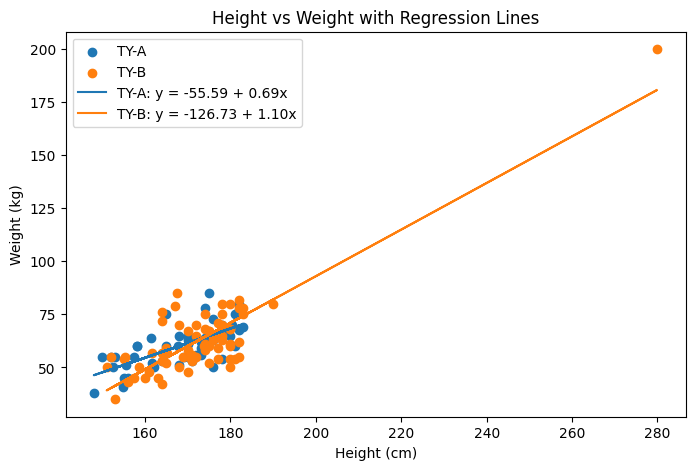

In [25]:
plt.figure(figsize=(8, 5))

plt.scatter(x_a, y_a, label="TY-A")
plt.scatter(x_b, y_b, label="TY-B")

line_a = beta_a[0] + beta_a[1] * x_a
line_b = beta_b[0] + beta_b[1] * x_b

plt.plot(x_a, line_a, label=f"TY-A: y = {beta_a[0]:.2f} + {beta_a[1]:.2f}x")
plt.plot(x_b, line_b, label=f"TY-B: y = {beta_b[0]:.2f} + {beta_b[1]:.2f}x")

plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.title("Height vs Weight with Regression Lines")
plt.legend()
plt.show()

B4 Gradient Descent — sklearn SGDRegressor

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor

x_a = df_a[["height_cm"]].values
y_a = df_a["weight_kg"].values

x_b = df_b[["height_cm"]].values
y_b = df_b["weight_kg"].values

scaler_a = StandardScaler()
scaler_b = StandardScaler()

x_a_scaled = scaler_a.fit_transform(x_a)
x_b_scaled = scaler_b.fit_transform(x_b)

model_a = SGDRegressor(max_iter=1000, tol=1e-3, random_state=42)
model_b = SGDRegressor(max_iter=1000, tol=1e-3, random_state=42)

model_a.fit(x_a_scaled, y_a)
model_b.fit(x_b_scaled, y_b)

print("TY-A")
print("beta0 =", model_a.intercept_[0])
print("beta1 =", model_a.coef_[0])
print("\nTY-B")
print("beta0 =", model_b.intercept_[0])
print("beta1 =", model_b.coef_[0])

TY-A
beta0 = 60.34035275776587
beta1 = 6.714361433510015

TY-B
beta0 = 62.99147260016291
beta1 = 17.16453212729501


SGD works by repeatedly updating the coefficients, so feature scaling helps it converge faster and more reliably. Without scaling, features with larger numerical values can affect the updates more strongly.

The Normal Equation directly calculates the optimal coefficients using matrix operations, so feature scaling is not required.

In [29]:
beta1_a = model_a.coef_[0] / scaler_a.scale_[0]
beta0_a = model_a.intercept_[0] - (model_a.coef_[0] * scaler_a.mean_[0] / scaler_a.scale_[0])

beta1_b = model_b.coef_[0] / scaler_b.scale_[0]
beta0_b = model_b.intercept_[0] - (model_b.coef_[0] * scaler_b.mean_[0] / scaler_b.scale_[0])

print("TY-A")
print("Original beta0 =", beta0_a)
print("Original beta1 =", beta1_a)

print("\nTY-B")
print("Original beta0 =", beta0_b)
print("Original beta1 =", beta1_b)

print("\nNormal Equation")
print("TY-A beta0 =", beta_a[0])
print("TY-A beta1 =", beta_a[1])

print("TY-B beta0 =", beta_b[0])
print("TY-B beta1 =", beta_b[1])

TY-A
Original beta0 = -55.47959513539598
Original beta1 = 0.687360372921727

TY-B
Original beta0 = -127.47743031016292
Original beta1 = 1.1028544484734661

Normal Equation
TY-A beta0 = -55.58646241587018
TY-A beta1 = 0.6884981472708057
TY-B beta0 = -126.73389052290416
TY-B beta1 = 1.0986647481175646


After converting the SGD coefficients back to the original height and weight units, the values should be close to the Normal Equation coefficients.

Small differences can occur because SGD is an iterative and approximate method, while the Normal Equation gives the exact solution for the linear regression problem.

B5 Error Metrics

In [30]:
def mae(y, y_pred):
    return np.mean(np.abs(y - y_pred))

In [31]:
def mse(y, y_pred):
    return np.mean((y - y_pred) ** 2)

In [32]:
def rmse(y, y_pred):
    return np.sqrt(mse(y, y_pred))

In [33]:
def r_squared(y, y_pred):
    y_mean = np.mean(y)
    
    ss_res = np.sum((y - y_pred) ** 2)
    ss_total = np.sum((y - y_mean) ** 2)
    
    return 1 - (ss_res / ss_total)

In [34]:
y_pred_normal_a = beta_a[0] + beta_a[1] * x_a.flatten()

In [35]:
y_pred_normal_b = beta_b[0] + beta_b[1] * x_b.flatten()

In [36]:
y_pred_sgd_a = model_a.predict(x_a_scaled)

In [37]:
y_pred_sgd_b = model_b.predict(x_b_scaled)


In [38]:
# TY-A Normal Equation
mae_normal_a = mae(y_a, y_pred_normal_a)
mse_normal_a = mse(y_a, y_pred_normal_a)
rmse_normal_a = rmse(y_a, y_pred_normal_a)
r2_normal_a = r_squared(y_a, y_pred_normal_a)

In [39]:
print("TY-A Normal Equation")
print("MAE:", mae_normal_a)
print("MSE:", mse_normal_a)
print("RMSE:", rmse_normal_a)
print("R2:", r2_normal_a)

TY-A Normal Equation
MAE: 5.784936603972785
MSE: 53.85621509802029
RMSE: 7.338679383786997
R2: 0.45648225510601215


In [40]:
# TY-A SGD
mae_sgd_a = mae(y_a, y_pred_sgd_a)
mse_sgd_a = mse(y_a, y_pred_sgd_a)
rmse_sgd_a = rmse(y_a, y_pred_sgd_a)
r2_sgd_a = r_squared(y_a, y_pred_sgd_a)

In [41]:
print("\nTY-A SGDRegressor")
print("MAE:", mae_sgd_a)
print("MSE:", mse_sgd_a)
print("RMSE:", rmse_sgd_a)
print("R2:", r2_sgd_a)


TY-A SGDRegressor
MAE: 5.784324936482721
MSE: 53.86353767692739
RMSE: 7.339178269869686
R2: 0.45640835552790127


In [42]:
# TY-B Normal Equation
mae_normal_b = mae(y_b, y_pred_normal_b)
mse_normal_b = mse(y_b, y_pred_normal_b)
rmse_normal_b = rmse(y_b, y_pred_normal_b)
r2_normal_b = r_squared(y_b, y_pred_normal_b)

In [43]:
print("\nTY-B Normal Equation")
print("MAE:", mae_normal_b)
print("MSE:", mse_normal_b)
print("RMSE:", rmse_normal_b)
print("R2:", r2_normal_b)


TY-B Normal Equation
MAE: 7.835214416118991
MSE: 99.0278196320844
RMSE: 9.9512722619816
R2: 0.7470002712727787


In [44]:
# TY-B SGD
mae_sgd_b = mae(y_b, y_pred_sgd_b)
mse_sgd_b = mse(y_b, y_pred_sgd_b)
rmse_sgd_b = rmse(y_b, y_pred_sgd_b)
r2_sgd_b = r_squared(y_b, y_pred_sgd_b)

In [45]:
print("\nTY-B SGDRegressor")
print("MAE:", mae_sgd_b)
print("MSE:", mse_sgd_b)
print("RMSE:", rmse_sgd_b)
print("R2:", r2_sgd_b)


TY-B SGDRegressor
MAE: 7.832370571539062
MSE: 99.03246987495558
RMSE: 9.951505909909091
R2: 0.7469883906700421


In [46]:
from sklearn.metrics import r2_score

print("TY-A Normal Equation")
print("Our R2:", r2_normal_a)
print("Sklearn R2:", r2_score(y_a, y_pred_normal_a))

print("\nTY-A SGDRegressor")
print("Our R2:", r2_sgd_a)
print("Sklearn R2:", r2_score(y_a, y_pred_sgd_a))

print("\nTY-B Normal Equation")
print("Our R2:", r2_normal_b)
print("Sklearn R2:", r2_score(y_b, y_pred_normal_b))

print("\nTY-B SGDRegressor")
print("Our R2:", r2_sgd_b)
print("Sklearn R2:", r2_score(y_b, y_pred_sgd_b))

TY-A Normal Equation
Our R2: 0.45648225510601215
Sklearn R2: 0.45648225510601215

TY-A SGDRegressor
Our R2: 0.45640835552790127
Sklearn R2: 0.45640835552790127

TY-B Normal Equation
Our R2: 0.7470002712727787
Sklearn R2: 0.7470002712727787

TY-B SGDRegressor
Our R2: 0.7469883906700421
Sklearn R2: 0.7469883906700421


Lower MAE, MSE and RMSE values indicate smaller prediction errors. A higher R² value indicates a better model fit.

In this case, a higher R² means that height explains more of the variation in weight. Therefore, the model with higher R² gives a better linear relationship between height and weight.

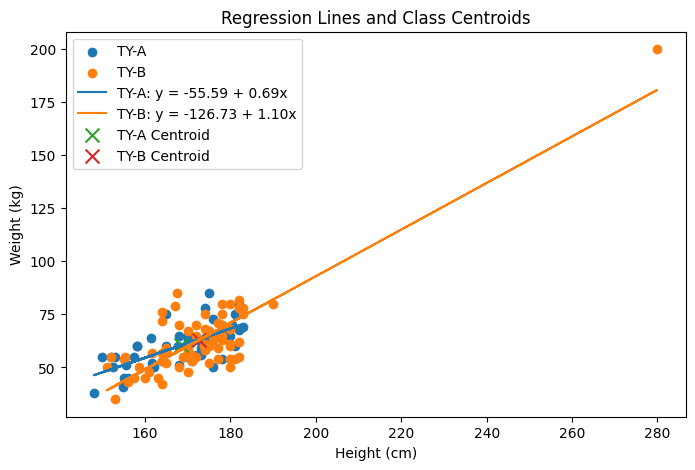

In [47]:
plt.figure(figsize=(8,5))

plt.scatter(x_a, y_a, label="TY-A")
plt.scatter(x_b, y_b, label="TY-B")

plt.plot(x_a, beta_a[0] + beta_a[1] * x_a,
         label=f"TY-A: y = {beta_a[0]:.2f} + {beta_a[1]:.2f}x")

plt.plot(x_b, beta_b[0] + beta_b[1] * x_b,
         label=f"TY-B: y = {beta_b[0]:.2f} + {beta_b[1]:.2f}x")

plt.scatter(np.mean(x_a), np.mean(y_a), marker="x", s=100, label="TY-A Centroid")
plt.scatter(np.mean(x_b), np.mean(y_b), marker="x", s=100, label="TY-B Centroid")

plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.title("Regression Lines and Class Centroids")
plt.legend()
plt.show()

In [52]:
r2_a_normal = r_squared(y_a, beta_a[0] + beta_a[1] * x_a.flatten())
r2_b_normal = r_squared(y_b, beta_b[0] + beta_b[1] * x_b.flatten())

print("TY-A")
print("beta0 =", beta_a[0])
print("beta1 =", beta_a[1])
print("R2 =", r2_a_normal)

print("\nTY-B")
print("beta0 =", beta_b[0])
print("beta1 =", beta_b[1])
print("R2 =", r2_b_normal)

if r2_a_normal > r2_b_normal:
    print("\nTY-A model is more reliable")
else:
    print("\nTY-B model is more reliable")

TY-A
beta0 = -55.58646241587018
beta1 = 0.6884981472708057
R2 = 0.45648225510601215

TY-B
beta0 = -126.73389052290416
beta1 = 1.0986647481175646
R2 = 0.7470002712727787

TY-B model is more reliable


TY-A has β0 = -55.59 and β1 = 0.68.
TY-B has β0 = -126.73 and β1 = 1.10.
β1 represents the change in predicted weight (kg) for a 1 cm increase in height.
For TY-A, R² = 0.4565, while for TY-B, R² = 0.7470.
TY-B has the higher R², so the TY-B model is more reliable for predicting weight from height.

B7 Take-Home (Submit with Notebook)

In [53]:
x = df_a["height_in"].values
y = df_a["weight_lb"].values

X = np.c_[np.ones(len(x)), x]

beta = np.linalg.inv(np.dot(X.T, X))
beta = np.dot(beta, X.T)
beta = np.dot(beta, y)

y_pred = beta[0] + beta[1] * x

r2 = r_squared(y, y_pred)

print("TY-A")
print("beta0 =", beta[0])
print("beta1 =", beta[1])
print("R2 =", r2)

TY-A
beta0 = 128.20580843961204
beta1 = 0.08093481006032954
R2 = 0.003009596394102476


 β1 has a different numerical value because height_in and weight_lb use different units than height_cm and weight_kg. The slope changes according to the units used, even though the physical relationship between height and weight remains the same.
R² should remain the same because changing the units does not change how well height explains the variation in weight.
This shows that regression coefficients depend on the choice of units, while R² is independent of the units. Therefore, β1 changes with unit conversion, but the goodness of fit remains the same.